# Customer Loyalty Classification

This notebook reproduces the multiclass part of a university team project.

**My contribution:** manual one-vs-rest logistic regression, batch gradient
descent, Nesterov acceleration, the scikit-learn comparison, and the
training-set-size experiment.

The task predicts four existing labels: `Occasional`, `Regular`, `Loyal`, and
`High_Value`. It is supervised classification, not unsupervised clustering.

## 1. Imports and project paths

Reusable model and preprocessing code lives in `src/`; the notebook is only an
explanation and experiment layer.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score

PROJECT_ROOT = Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from loyalty_segmentation.data import prepare_data
from loyalty_segmentation.model import OneVsRestLogisticRegression

## 2. Load and inspect the dataset

Download the CSV using the instructions in `data/README.md`. The dataset
contains demographic, behavioural, and transactional features for 50,000
customers.

In [2]:
data_path = PROJECT_ROOT / "data" / "retail_customer_segmentation.csv"
if not data_path.exists():
    raise FileNotFoundError(
        "Download retail_customer_segmentation.csv as described in data/README.md"
    )

df = pd.read_csv(data_path)
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
df["customer_segment"].value_counts().to_frame("customers")

Shape: (50000, 14)
Missing values: 18532


,customers
customer_segment,
Occasional,22109
Regular,13455
Loyal,9163
High_Value,5273


## 3. Leakage-safe preprocessing

The split happens first. Imputation, one-hot encoding, and scaling are then
fitted only on the training set and applied to the test set.

In [3]:
prepared = prepare_data(df)
print("Training rows:", len(prepared.y_train))
print("Test rows:", len(prepared.y_test))
print("Features after encoding:", prepared.x_train.shape[1])

Training rows: 40000
Test rows: 10000
Features after encoding: 16


## 4. Train manual and reference models

The manual implementation trains one binary logistic model per class. Final
predictions use the class with the largest score. Both optimizers use 200 full
batch epochs.

In [4]:
models = {
    "Manual GD": OneVsRestLogisticRegression(
        optimizer="gd", learning_rate=0.1, epochs=200
    ),
    "Manual Nesterov": OneVsRestLogisticRegression(
        optimizer="nesterov", learning_rate=0.1, epochs=200, momentum=0.9
    ),
    "sklearn LogisticRegression": LogisticRegression(max_iter=1000),
}

rows = []
for name, model in models.items():
    model.fit(prepared.x_train, prepared.y_train)
    prediction = model.predict(prepared.x_test)
    rows.append({
        "model": name,
        "accuracy": accuracy_score(prepared.y_test, prediction),
        "macro_precision": precision_score(
            prepared.y_test, prediction, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            prepared.y_test, prediction, average="macro", zero_division=0
        ),
    })

results = pd.DataFrame(rows).set_index("model")
(results * 100).round(2).rename(columns={
    "accuracy": "accuracy_%",
    "macro_precision": "macro_precision_%",
    "macro_recall": "macro_recall_%",
})

,accuracy_%,macro_precision_%,macro_recall_%
model,,,
Manual GD,64.25,63.83,56.58
Manual Nesterov,65.80,64.68,60.70
sklearn LogisticRegression,66.43,64.90,62.98


## 5. Convergence

Nesterov uses a look-ahead point and momentum. On this dataset it reaches a
lower one-vs-rest log loss than standard gradient descent within the same
number of epochs.

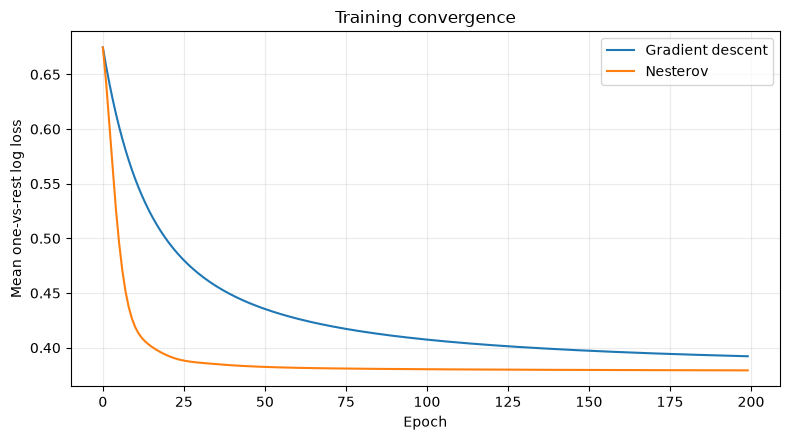

In [5]:
gd = models["Manual GD"]
nesterov = models["Manual Nesterov"]

plt.figure(figsize=(8, 4.5))
plt.plot(gd.loss_history_, label="Gradient descent")
plt.plot(nesterov.loss_history_, label="Nesterov")
plt.xlabel("Epoch")
plt.ylabel("Mean one-vs-rest log loss")
plt.title("Training convergence")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

## Conclusion

- Nesterov improves both accuracy and macro recall over ordinary batch GD.
- The manual implementation remains close to the scikit-learn baseline.
- Macro recall is especially important because the four classes are imbalanced.
- For production use, model selection should also include cross-validation,
  probability calibration, and monitoring for data drift.